> Notebook-friendly copy of `part-I/1.5-pandas-practice-exercises.ipynb`, generated by `tools/make_live.py`. Edit the book notebook, not this file.

# Practice Exercises

In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

**ℹ️ How to use these exercises**

Attempt each from scratch in the empty code cell. Import pandas as `pd` and numpy as `np`, seed any randomness with `default_rng`, and keep units in your column names.

## Exercise 1: A DataFrame and a column mean

Build a DataFrame with columns `temp_celsius = [18.2, 17.5, 19.1, 16.8]` and `discharge_m3s = [48.0, 51.2, 47.5, 53.1]`. Print the column dtypes and the mean temperature, rounded to two decimals.

In [3]:
TABLE1= pd.DataFrame(
    {"temp_celsius" : [18.2, 17.5, 19.1, 16.8],
     "discharge_m3s" : [48.0, 51.2, 47.5, 53.1]},
    index = [1,2,3,4]
)
print(f"mean temperature: {TABLE1["temp_celsius"].mean(): .2f}")
print(TABLE1["temp_celsius"].dtype)
print(TABLE1["discharge_m3s"].dtype)
TABLE1

mean temperature:  17.90
float64
float64


,temp_celsius,discharge_m3s
1,18.2,48.0
2,17.5,51.2
3,19.1,47.5
4,16.8,53.1


## Exercise 2: Write and read a CSV with dates

Build a DataFrame with a `date` column (`"2024-06-01"`, `"2024-06-02"`, `"2024-06-03"`) and a `temp_celsius` column. Write it to `_files/obs.csv` without the index, then read it back with `parse_dates=["date"]` and print the dtypes.

In [4]:
from pathlib import Path
# Create a DataFrame with dates and temperatures
TABLE2 = pd.DataFrame({
    "date": ["2024-06-01", "2024-06-02", "2024-06-03"],
    "temp_celsius": [20.5, 21.3, 19.8]
})

# Create the _files directory if it does not already exist
Path("_files").mkdir(exist_ok=True)

# Write the DataFrame to a CSV file without saving the index
TABLE2.to_csv("_files/obs.csv", index=False) #because we want csv written without the index

# Read the CSV file back and convert the date column to datetime
TABLE2_read = pd.read_csv("_files/obs.csv", parse_dates=["date"]) #parse_dates=["date"] is what tells Pandas to convert the date column into a datetime data type when reading the CSV, so from str to a value.

# Print the data types of each column
print(TABLE2_read.dtypes)
TABLE2

date            datetime64[ns]
temp_celsius           float64
dtype: object


,date,temp_celsius
0,2024-06-01,20.5
1,2024-06-02,21.3
2,2024-06-03,19.8


## Exercise 3: Label, position, and mask

Given

```python
df = pd.DataFrame({"station": ["BAS", "LUG", "JFJ"], "temp_celsius": [18.0, 21.0, -1.0]},
                  index=["a", "b", "c"])
```

print the temperature at label `"b"`, the whole first row by position, and all rows whose temperature is below 0 °C.

In [5]:
df = pd.DataFrame({"station": ["BAS", "LUG", "JFJ"], "temp_celsius": [18.0, 21.0, -1.0]},
                  index=["a", "b", "c"])
print(df.loc["b", "temp_celsius"])
print(df.iloc[0])
print(df[df["temp_celsius"] < 0])
df

21.0
station          BAS
temp_celsius    18.0
Name: a, dtype: object
  station  temp_celsius
c     JFJ          -1.0


,station,temp_celsius
a,BAS,18.0
b,LUG,21.0
c,JFJ,-1.0


## Exercise 4: `.isel` and `.sel` on a DataArray

The block below stores ten days of temperature at three stations twice: as an xarray `DataArray` with dimensions `time` and `station`, and as a DataFrame with the dates as rows and the stations as columns. Using `temp_da`, print:

1. every station's first day, by position with `.isel` — and the same row of `temp_df` with `.iloc`;
2. JFJ on 5 June, by label with `.sel` — and the same cell of `temp_df` with `.loc`;
3. LUG's last three days — `.isel` also accepts a list of positions;
4. the BAS reading nearest to 18:00 on 7 June, and the date it was taken. Select the station first and apply `method="nearest"` to the time alone: `.sel` applies the method to every dimension it is given, and the station names cannot be "nearest" to anything.

In a comment, say why item 4 returns the day it does, and what `temp_da.isel(station=0)` would return if the array had been built with its dimensions in the other order, `("station", "time")`.

```python
import xarray as xr

rng = np.random.default_rng(2)
dates = pd.date_range("2024-06-01", periods=10, freq="D")
temp_celsius = np.array([18.0, 21.0, -1.0]) + rng.normal(0, 1.5, size=(10, 3))   # (time, station)

temp_da = xr.DataArray(temp_celsius, dims=("time", "station"),
                       coords={"time": dates, "station": ["BAS", "LUG", "JFJ"]},
                       attrs={"units": "degC"})
temp_df = pd.DataFrame(temp_celsius, index=dates, columns=["BAS", "LUG", "JFJ"])
```

In [6]:
import xarray as xr

rng = np.random.default_rng(2)
dates = pd.date_range("2024-06-01", periods=10, freq="D")
temp_celsius = np.array([18.0, 21.0, -1.0]) + rng.normal(0, 1.5, size=(10, 3))   # (time, station)

temp_da = xr.DataArray(temp_celsius, dims=("time", "station"),
                       coords={"time": dates, "station": ["BAS", "LUG", "JFJ"]},
                       attrs={"units": "degC"})
temp_df = pd.DataFrame(temp_celsius, index=dates, columns=["BAS", "LUG", "JFJ"])

print(temp_da.isel(time=0))
print(temp_df.iloc[0])
print(temp_da.sel(time="2024-06-05",station="JFJ").item())
print(temp_df.loc["2024-06-05","JFJ"])
print(temp_da.isel(time=[7,8,9]).sel(station="LUG"))
#.isel() versus .iloc(): Both select data by position.
#.sel() versus .loc(): Both select data by label.
bas = temp_da.sel(station="BAS")
target_time = pd.Timestamp("2024-06-07 18:00")
nearest = bas.sel(time=target_time, method="nearest")
print(nearest)
print(nearest.time.values)
#Comment: The nearest reading is from 8 June because the observations
# are daily at midnight. 8 June at 00:00 is 6 hours from the target,
# whereas 7 June at 00:00 is 18 hours away.
# If the dimensions were ("station", "time"), isel(station=0)
# would still select BAS, returning its temperatures across all 10 days.

<xarray.DataArray (station: 3)> Size: 24B
array([18.28358007, 20.21587734, -1.61959532])
Coordinates:
  * station  (station) <U3 36B 'BAS' 'LUG' 'JFJ'
    time     datetime64[ns] 8B 2024-06-01
Attributes:
    units:    degC
BAS    18.283580
LUG    20.215877
JFJ    -1.619595
Name: 2024-06-01 00:00:00, dtype: float64
-0.3175628931387168
-0.3175628931387168
<xarray.DataArray (time: 3)> Size: 24B
array([21.49585651, 22.17477149, 18.4058828 ])
Coordinates:
  * time     (time) datetime64[ns] 24B 2024-06-08 2024-06-09 2024-06-10
    station  <U3 12B 'LUG'
Attributes:
    units:    degC
<xarray.DataArray ()> Size: 8B
array(18.28205263)
Coordinates:
    time     datetime64[ns] 8B 2024-06-08
    station  <U3 12B 'BAS'
Attributes:
    units:    degC
2024-06-08T00:00:00.000000000


## Exercise 5: Resample and rolling

Build a 40-day daily Series indexed by date (`np.random.default_rng(0)`, mean 18, std 2). Print the monthly means and the first five values of the 3-day rolling mean, both rounded to two decimals.

In [7]:
rng= np.random.default_rng(0)
random= pd.Series
dates = pd.date_range("2024-06-01", periods=40, freq="D")
temps = pd.Series(rng.normal(18, 2, size=40), index=dates)
# Calculate and print the monthly means, rounded to 2 decimal places
print(temps.resample("ME").mean().round(2))
#resample("ME") groups the daily observations by calendar month, using each month's end as the label.
# Calculate and print the first five values of the 3-day rolling mean
print(temps.rolling(window=3).mean().head().round(2))
#rolling(window=3) calculates averages over three consecutive observations.
#The first two values will be NaN because there aren't yet three observations available.

2024-06-30    17.76
2024-07-31    18.25
Freq: ME, dtype: float64
2024-06-01      NaN
2024-06-02      NaN
2024-06-03    18.42
2024-06-04    18.41
2024-06-05    18.14
Freq: D, dtype: float64


## Exercise 6: Group and aggregate

Given

```python
df = pd.DataFrame({"station": ["BAS", "BAS", "LUG", "LUG"],
                   "temp_celsius": [18.0, 19.0, 21.0, 22.0]})
```

compute the mean temperature per station and print it as a dict.

In [14]:
df = pd.DataFrame({
    "station": ["BAS", "BAS", "LUG", "LUG"],
    "temp_celsius": [18.0, 19.0, 21.0, 22.0]
})

# Calculate the mean temperature for each station
means = df.groupby("station")["temp_celsius"].mean()

# Convert the result to a dictionary and print it
print(means.to_dict())
df

{'BAS': 18.5, 'LUG': 21.5}


,station,temp_celsius
0,BAS,18.0
1,BAS,19.0
2,LUG,21.0
3,LUG,22.0


## Exercise 7: Handle a gap three ways

Given `s = pd.Series([1.0, np.nan, np.nan, 4.0, 5.0])`, print the forward-filled series, the linearly interpolated series, and the NaN-skipping mean. Note in a comment why the three differ.

In [16]:
s = pd.Series([1.0, np.nan, np.nan, 4.0, 5.0])
print("with gaps:  ", s.tolist())
print("ffill:      ", s.ffill().tolist())                  # carry forward
print("interpolate:", s.interpolate().tolist())
print("NaN-skipping mean:", s.mean())
# The three differ because forward-fill copies the previous value,
# interpolation estimates values along a straight line between known values,
# and mean calculates the average of all non-missing values.

with gaps:   [1.0, nan, nan, 4.0, 5.0]
ffill:       [1.0, 1.0, 1.0, 4.0, 5.0]
interpolate: [1.0, 2.0, 3.0, 4.0, 5.0]
NaN-skipping mean: 3.3333333333333335


## Exercise 8: Join two tables

Given an observations table and a metadata table that share a `station` key, left-join the elevation onto the observations and print the result.

```python
obs = pd.DataFrame({"station": ["BAS", "LUG"], "temp_celsius": [18.0, 21.0]})
meta = pd.DataFrame({"station": ["BAS", "LUG"], "elevation_m": [316, 273]})
```

Then stack the row below — a third station that reports only temperature — onto the joined table with `concat`, and print the result. Which cell comes out missing, and why?

```python
jfj = pd.DataFrame({"station": ["JFJ"], "temp_celsius": [-1.0]})
```

In [23]:
obs = pd.DataFrame({"station": ["BAS", "LUG"], "temp_celsius": [18.0, 21.0]})
meta = pd.DataFrame({"station": ["BAS", "LUG"], "elevation_m": [316, 273]})
joined = obs.merge(meta, on="station", how="left")
print(joined)
jfj = pd.DataFrame({"station": ["JFJ"], "temp_celsius": [-1.0]})
result = pd.concat([joined, jfj], ignore_index=True)
print(result)

  station  temp_celsius  elevation_m
0     BAS          18.0          316
1     LUG          21.0          273
  station  temp_celsius  elevation_m
0     BAS          18.0        316.0
1     LUG          21.0        273.0
2     JFJ          -1.0          NaN


## Exercise 9: A log-scale axis, and counting past a threshold

River discharge is a classic right-skewed variable: most days sit near base flow, with a long tail of rare, much larger flood events.

```python
rng = np.random.default_rng(1)
discharge_m3s = pd.Series(np.exp(rng.normal(3.4, 1.3, 300)))
```

1. Plot a histogram of `discharge_m3s` with `.plot(kind="hist")`, on default (linear) axes, then again with `logy=True`. Which view makes the long tail easier to read?
2. Build a boolean mask for discharge above 100 m³ s⁻¹ (a "flood" threshold), filter `discharge_m3s` with it, and print how many of the 300 values exceed it.

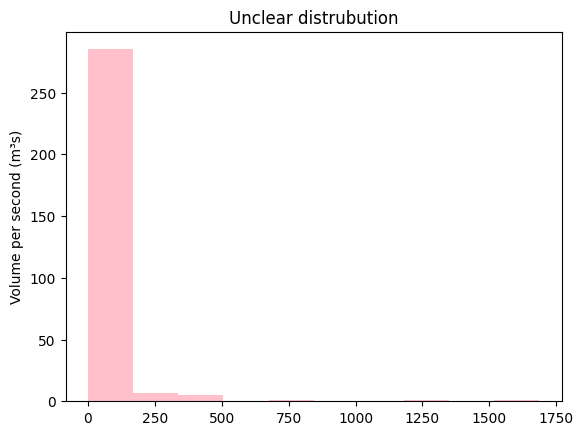

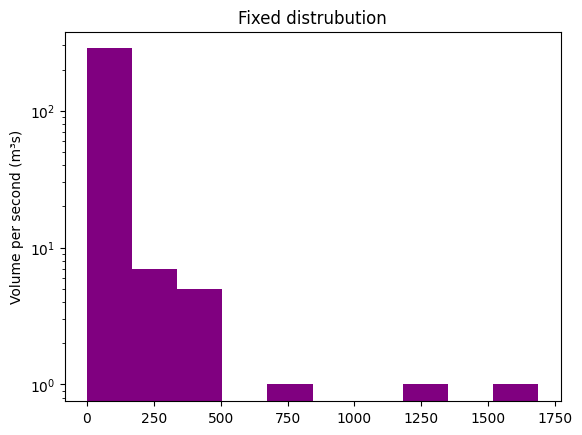

25


In [34]:
rng = np.random.default_rng(1)
discharge_m3s = pd.Series(np.exp(rng.normal(3.4, 1.3, 300)))
discharge_m3s.plot(kind="hist", ylabel="Volume per second (m³s)", color="pink", title="Unclear distrubution")
plt.show()
discharge_m3s.plot(kind="hist", ylabel="Volume per second (m³s)", logy= True, color="purple",title="Fixed distrubution")
plt.show()
discharge_above_100= discharge_m3s > 100
# Filter the Series to keep only values above 100
flood_values = discharge_m3s[discharge_above_100]
print(len(flood_values))

## Exercise 10: Filtered vs. unfiltered histogram

```python
rng = np.random.default_rng(0)
temp_celsius = pd.Series(rng.normal(18.0, 2.0, 200))
temp_celsius[:5] = -999.0     # a stuck sensor: five obviously invalid readings
```

1. Plot a histogram of the raw `temp_celsius` values with `.plot(kind="hist")`. What does the stuck sensor do to the plot?
2. Build a boolean mask that keeps only values above −50 °C, filter the Series with it, and plot the histogram again. In one comment, say which of the two plots you would trust.
3. Finally, mark the stuck readings in `temp_celsius` itself as missing: set every value below −50 °C to `np.nan` with a masked `.loc` assignment, then print the mean of the result next to the mean of the filtered Series from step 2. Why do the two agree?

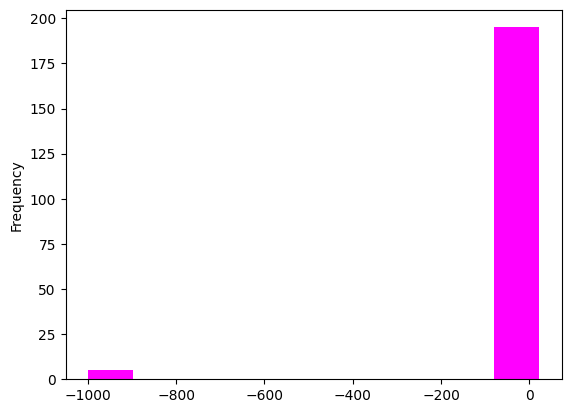

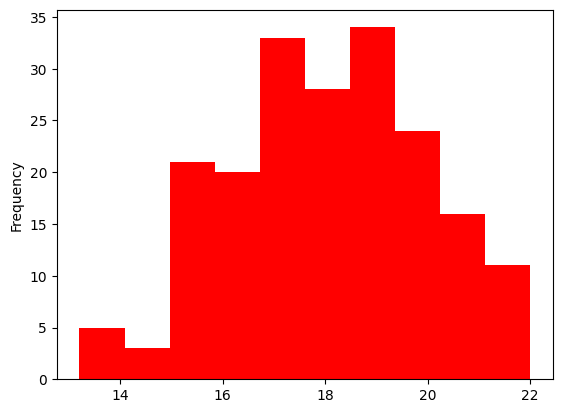

Mean after replacing invalid readings with NaN: 18.02922409415129
Mean of filtered Series: 18.02922409415129


In [43]:
rng = np.random.default_rng(0)
temp_celsius = pd.Series(rng.normal(18.0, 2.0, 200))
temp_celsius[:5] = -999.0     # a stuck sensor: five obviously invalid readings
temp_celsius.plot(kind="hist", color="magenta")
plt.show()
#Because it has to adapt such a large scale, it does not show the distribution of the valid date, and instead shows only two bars
corrected= temp_celsius > -50
distrubution= temp_celsius[corrected]
distrubution.plot(kind="hist", color="red")
plt.show()
# method 2
temp_celsius.loc[temp_celsius < -50] = np.nan
# Print the mean of the Series containing NaN values and the filtered Series
print("Mean after replacing invalid readings with NaN:", temp_celsius.mean())
print("Mean of filtered Series:", distrubution.mean())
#both methods do not account for the extreme outlier